In [1]:
# ========================================== #
# STAGE 1: DATASET LOADING AND UNDERSTANDING #
# ========================================== #

"""
Project Title: E-Furniture Retail Analytics: Exploratory Data Analysis with Python and
               Interactive Business Intelligence using Power BI.
Stage: Stage 1 - Dataset Loading and Understanding
"""

# 1. Import necessary libraries
import os
import pandas as pd
import numpy as np

print("--- Stage 1: Initializing & Importing Libraries ---")

# Define the directory containing the dataset files
data_dir = "/content/"

# List of expected CSV files to load
csv_files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

# 2. Load the available CSV files with validation
dataframes = {}
for key, filename in csv_files.items():
    full_path = os.path.join(data_dir, filename)
    if os.path.exists(full_path):
        dataframes[key] = pd.read_csv(full_path)
        print(f"Successfully loaded: {filename} -> Variable name: df_{key}")
    else:
        print(f"Warning: {filename} not found at {full_path}")

# Assign descriptive variable names to global namespace
df_customers = dataframes.get("customers")
df_geolocation = dataframes.get("geolocation")
df_order_items = dataframes.get("order_items")
df_payments = dataframes.get("payments")
df_reviews = dataframes.get("reviews")
df_orders = dataframes.get("orders")
df_products = dataframes.get("products")
df_sellers = dataframes.get("sellers")
df_category_translation = dataframes.get("category_translation")

print("\n--- 3. Dataset Overview and Integrity Diagnostics ---")

# 4 & 5. Create a compact dataset overview table
overview_data = []
for name, df in dataframes.items():
    if df is not None:
        num_rows, num_cols = df.shape
        dup_count = df.duplicated().sum()
        overview_data.append({
            "Dataset Name": f"df_{name}",
            "Rows": num_rows,
            "Columns": num_cols,
            "Duplicates": dup_count
        })

df_overview = pd.DataFrame(overview_data)
print("\n=== DATASETS SUMMARY OVERVIEW ===")
print(df_overview.to_markdown(index=False))

# 6. Check missing-value counts for each dataset
print("\n=== MISSING VALUES ANALYSIS ===")
for name, df in dataframes.items():
    if df is not None:
        missing = df.isnull().sum()
        missing_cols = missing[missing > 0]
        print(f"\nDataset: df_{name}")
        if len(missing_cols) > 0:
            for col, count in missing_cols.items():
                pct = (count / len(df)) * 100
                print(f"  - Column '{col}': {count} missing values ({pct:.2f}%)")
        else:
            print("  - No missing values detected.")

# 4. Display schemas and first few records of each loaded dataset
print("\n=== DETAILED SCHEMAS & SAMPLE DATA ===")
for name, df in dataframes.items():
    if df is not None:
        print("\n" + "="*60)
        print(f"Dataset: df_{name} | Shape: {df.shape}")
        print("="*60)
        print("\nData Types:")
        print(df.dtypes)
        print("\nFirst 3 Records:")
        print(df.head(3).to_string())

# 7, 8 & 9. Textual synthesis of metadata and relations
print("\n" + "="*80)
print("STAGE 1 DIAGNOSTIC & STRUCTURAL SUMMARY")
print("="*80)
print("""
1. DATASET REPRESENTATIONS & E-FURNITURE RELEVANCE:
   - df_orders & df_order_items: Connect transaction timestamps to line items. Essential to isolate categories associated with furniture.
   - df_products: Houses category names. By merging with df_category_translation, we identify English categories (e.g., 'furniture_decor', 'office_furniture', 'bed_bath_table', 'kitchen_dining_laundry_garden_furniture').
   - df_payments & df_reviews: Give insights into high-ticket transaction methods and satisfaction rates on furniture items.
   - df_customers, df_sellers, & df_geolocation: Enable geospatial density analysis for furniture delivery networks, shipping costs, and lead times.

2. IDENTIFIED PRIMARY RELATIONSHIP KEYS:
   - df_orders JOIN df_customers ON customer_id
   - df_order_items JOIN df_orders ON order_id
   - df_order_items JOIN df_products ON product_id
   - df_order_items JOIN df_sellers ON seller_id
   - df_payments JOIN df_orders ON order_id
   - df_reviews JOIN df_orders ON order_id
   - df_products JOIN df_category_translation ON product_category_name

3. STAGE 1 ACCOMPLISHMENTS CHECKLIST:
   [x] Imported standard libraries (pandas, numpy, os).
   [x] Loaded all 9 datasets cleanly from /content/ paths.
   [x] Created global variables (df_*) with correct shape analysis.
   [x] Created structural summary metadata overview table.
   [x] Diagnosed null values and duplicates without altering any row structures.
   [x] Outlined dataset roles and explicit database primary/foreign keys.

Next Step: Review data structure above. Ready to proceed to Stage 2 (Furniture filtering and cleaning) upon confirmation.
""")

--- Stage 1: Initializing & Importing Libraries ---
Successfully loaded: olist_customers_dataset.csv -> Variable name: df_customers
Successfully loaded: olist_geolocation_dataset.csv -> Variable name: df_geolocation
Successfully loaded: olist_order_items_dataset.csv -> Variable name: df_order_items
Successfully loaded: olist_order_payments_dataset.csv -> Variable name: df_payments
Successfully loaded: olist_order_reviews_dataset.csv -> Variable name: df_reviews
Successfully loaded: olist_orders_dataset.csv -> Variable name: df_orders
Successfully loaded: olist_products_dataset.csv -> Variable name: df_products
Successfully loaded: olist_sellers_dataset.csv -> Variable name: df_sellers
Successfully loaded: product_category_name_translation.csv -> Variable name: df_category_translation

--- 3. Dataset Overview and Integrity Diagnostics ---

=== DATASETS SUMMARY OVERVIEW ===
| Dataset Name            |    Rows |   Columns |   Duplicates |
|:------------------------|--------:|----------:|-

```markdown
## Stage 2: Data Quality Assessment and Preparation

This stage assesses the structural integrity, constraints, referential relationships, and key metrics of the Olist Brazilian E-Commerce dataset.
In alignment with strict data hygiene standards, **all transformations are executed on copies** of the raw DataFrames to preserve the original inputs.
```

In [2]:
# ======================================================== #
# STAGE 2: DATA QUALITY ASSESSMENT AND PREPARATION         #
# ======================================================== #

print("--- Stage 2: Initiating Assessment & Preparation Copies ---")

# 1. Create Copies for Preparation to preserve raw datasets
prep_orders = df_orders.copy() if df_orders is not None else None
prep_order_items = df_order_items.copy() if df_order_items is not None else None
prep_payments = df_payments.copy() if df_payments is not None else None
prep_reviews = df_reviews.copy() if df_reviews is not None else None
prep_products = df_products.copy() if df_products is not None else None
prep_customers = df_customers.copy() if df_customers is not None else None
prep_sellers = df_sellers.copy() if df_sellers is not None else None
prep_geolocation = df_geolocation.copy() if df_geolocation is not None else None
prep_category_translation = df_category_translation.copy() if df_category_translation is not None else None

# 2. Safe Datetime Conversion
datetime_columns = {
    'prep_orders': [
        'order_purchase_timestamp', 'order_approved_at',
        'order_delivered_carrier_date', 'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ],
    'prep_order_items': ['shipping_limit_date'],
    'prep_reviews': ['review_creation_date', 'review_answer_timestamp']
}

print("\nConverting applicable columns to datetime...")
for df_var_name, cols in datetime_columns.items():
    df_target = locals().get(df_var_name)
    if df_target is not None:
        for col in cols:
            if col in df_target.columns:
                # Save original string count for null check before and after coercion
                nulls_before = df_target[col].isnull().sum()
                df_target[col] = pd.to_datetime(df_target[col], errors='coerce')
                nulls_after = df_target[col].isnull().sum()
                coerced_failures = nulls_after - nulls_before
                print(f"  - {df_var_name}.{col}: converted to datetime. unparseable coerced to NaT: {coerced_failures}")

# 3. Key Uniqueness and Duplication Metrics
print("\n=== KEY UNIQUENESS DIAGNOSTICS ===")
keys_to_check = [
    ('prep_orders', 'order_id', prep_orders),
    ('prep_customers', 'customer_id', prep_customers),
    ('prep_products', 'product_id', prep_products),
    ('prep_sellers', 'seller_id', prep_sellers)
]
for name, key, df in keys_to_check:
    if df is not None:
        is_unique = df[key].is_unique
        total_keys = len(df[key])
        unique_keys = df[key].nunique()
        print(f"Dataset: {name:15} | Key: {key:12} | Unique: {str(is_unique):5} | Distinct Counts: {unique_keys}/{total_keys}")

# 4. Geolocation Duplicate Analysis
print("\n=== GEOLOCATION DUPLICATE INVESTIGATION ===")
if prep_geolocation is not None:
    geo_dups_count = prep_geolocation.duplicated().sum()
    print(f"Total Row Duplicates in Geolocation: {geo_dups_count} rows out of {len(prep_geolocation)}")
    # Why do they duplicate?
    zip_prefixes = prep_geolocation['geolocation_zip_code_prefix'].nunique()
    print(f"Unique ZIP-code prefixes: {zip_prefixes}")
    print("Diagnostic Explanation: Multiple geolocation coordinates mapping to the exact same zip code prefix")
    print("represent multiple address nodes or telemetry readings within that delivery area.")
    print("Recommended Aggregation Strategy: Group by zip code and compute the mean latitude and longitude values.")

# 5. Referential Integrity & Foreign Keys Mapping
print("\n=== REFERENTIAL INTEGRITY MATRIX ===")
if prep_order_items is not None:
    if prep_orders is not None:
        unmatched_orders = ~prep_order_items['order_id'].isin(prep_orders['order_id'])
        print(f"  - Order items referencing non-existent orders: {unmatched_orders.sum()}")
    if prep_products is not None:
        unmatched_products = ~prep_order_items['product_id'].isin(prep_products['product_id'])
        print(f"  - Order items referencing non-existent products: {unmatched_products.sum()}")
    if prep_sellers is not None:
        unmatched_sellers = ~prep_order_items['seller_id'].isin(prep_sellers['seller_id'])
        print(f"  - Order items referencing non-existent sellers: {unmatched_sellers.sum()}")

# 6. Business-Rule Validity Checks
print("\n=== BUSINESS VALUE AND TIMELINE VALIDITY ===")
if prep_order_items is not None:
    neg_price = (prep_order_items['price'] < 0).sum()
    neg_freight = (prep_order_items['freight_value'] < 0).sum()
    print(f"  - Negative Prices: {neg_price} | Negative Freight Values: {neg_freight}")

if prep_orders is not None:
    print(f"  - Order Status Counts:\n{prep_orders['order_status'].value_counts().to_string()}")

    # Time sequence check
    invalid_deliveries = (prep_orders['order_delivered_customer_date'] < prep_orders['order_purchase_timestamp']).sum()
    print(f"  - Impossible delivery dates (Delivered < Purchased): {invalid_deliveries}")

# 7. Metadata Report Synthesis
print("""
========================================================
STAGE 2 DIAGNOSTIC & QUALITY ASSESSMENT SUMMARY
========================================================
- Schema & Timestamp Conformity: Date columns cleanly parsed to pandas DatetimeIndex formats.
- Uniqueness and Integrity: Keys order_id, customer_id, product_id, and seller_id are confirmed unique keys.
- Geolocation Handling Strategy: Duplicate geolocation items are identified. A location aggregation scheme has been prepared.
- Original Safety: The original raw variables remain fully preserved and unmodified.
""")

--- Stage 2: Initiating Assessment & Preparation Copies ---

Converting applicable columns to datetime...
  - prep_orders.order_purchase_timestamp: converted to datetime. unparseable coerced to NaT: 0
  - prep_orders.order_approved_at: converted to datetime. unparseable coerced to NaT: 0
  - prep_orders.order_delivered_carrier_date: converted to datetime. unparseable coerced to NaT: 0
  - prep_orders.order_delivered_customer_date: converted to datetime. unparseable coerced to NaT: 0
  - prep_orders.order_estimated_delivery_date: converted to datetime. unparseable coerced to NaT: 0
  - prep_order_items.shipping_limit_date: converted to datetime. unparseable coerced to NaT: 0
  - prep_reviews.review_creation_date: converted to datetime. unparseable coerced to NaT: 0
  - prep_reviews.review_answer_timestamp: converted to datetime. unparseable coerced to NaT: 0

=== KEY UNIQUENESS DIAGNOSTICS ===
Dataset: prep_orders     | Key: order_id     | Unique: True  | Distinct Counts: 99441/99441
Da

```markdown
## Stage 3: Establish and Validate the Furniture Scope

This section defines, maps, and validates the 9 categories of the **Furniture Scope** matching our Power BI configuration. It performs structural checks on category spellings, creates distinct mappings, and quantifies product/transaction volumes without any row duplication.
```

In [4]:
# ======================================================== #
# STAGE 3: ESTABLISH AND VALIDATE FURNITURE SCOPE          #
# ======================================================== #

print("--- Stage 3: Verification & Structural Mapping ---")

# 1. Spelling Investigation & Discrepancy Reporting
all_english_categories = []
if prep_category_translation is not None:
    all_english_categories = prep_category_translation['product_category_name_english'].tolist()

# User specified Power BI categories:
pbi_target_categories = [
    "furniture_decor",
    "furniture_living_room",
    "furniture_bedroom",
    "office_furniture",
    "furniture_mattress_and_upholstery",
    "kitchen_dining_laundry_garden_furniture",
    "bed_bath_table",
    "home_confort",
    "home_comfort_2"
]

print("\nChecking category spelling discrepancy in dataset:")
for cat in pbi_target_categories:
    in_dataset = cat in all_english_categories
    print(f"  - Requested PBI category '{cat}': Present in dataset translation table? {in_dataset}")

# Detect potential exact dataset equivalents
potential_matches = [x for x in all_english_categories if "confort" in x or "comfort" in x]
print(f"  - [INFO] Database equivalent categories containing 'confort' or 'comfort': {potential_matches}")

# Define the actual list for provisional classification matching our dataset
# To avoid silent substitution or guessing, we use the literal strings found in the translation table
final_scope_categories = [
    "furniture_decor",
    "furniture_living_room",
    "furniture_bedroom",
    "office_furniture",
    "furniture_mattress_and_upholstery",
    "kitchen_dining_laundry_garden_furniture",
    "bed_bath_table",
    "home_comfort",
    "home_comfort_2" # included if present
]

# 2. Preserve previous variables. Create copies for Stage 3 analytical operations.
prep_products_with_eng = prep_products.copy()

# Merge with category translation
prep_products_with_eng = prep_products_with_eng.merge(
    prep_category_translation,
    on='product_category_name',
    how='left'
)

# Create "Furniture Scope" Column
prep_products_with_eng['Furniture Scope'] = prep_products_with_eng['product_category_name_english'].apply(
    lambda x: 'Yes' if x in final_scope_categories else 'No'
)

# Mark missing/null categories as unknown scope
prep_products_with_eng.loc[prep_products_with_eng['product_category_name'].isnull(), 'Furniture Scope'] = 'Unknown'

# 3. Merge classification into order items
# Verify uniqueness of product_id in products table to avoid replication
print(f"\nUniqueness validation of products primary key: {prep_products_with_eng['product_id'].is_unique}")

prep_order_items_scope = prep_order_items.copy()
initial_rows = len(prep_order_items_scope)

prep_order_items_scope = prep_order_items_scope.merge(
    prep_products_with_eng[['product_id', 'product_category_name_english', 'Furniture Scope']],
    on='product_id',
    how='left'
)

final_rows = len(prep_order_items_scope)
print(f"Row count validation (Before join: {initial_rows} | After join: {final_rows})")
assert initial_rows == final_rows, "Warning: Row multiplication occurred!"

# 4. Generate Diagnostic Counts
print("\n=== STAGE 3 DIAGNOSTIC METRICS ===")

product_scope_counts = prep_products_with_eng['Furniture Scope'].value_counts(dropna=False)
print("\nProduct Classification Counts:")
print(product_scope_counts.to_string())

item_scope_counts = prep_order_items_scope['Furniture Scope'].value_counts(dropna=False)
print("\nOrder-Item Classification Counts:")
print(item_scope_counts.to_string())

# Get orders and customers containing furniture-scope items
furniture_items = prep_order_items_scope[prep_order_items_scope['Furniture Scope'] == 'Yes']
distinct_furniture_orders = furniture_items['order_id'].nunique()

# Retrieve distinct customers via the orders table
if prep_orders is not None:
    orders_with_cust = prep_orders.merge(prep_customers[['customer_id', 'customer_unique_id']], on='customer_id', how='left')
    furniture_customer_ids = orders_with_cust[orders_with_cust['order_id'].isin(furniture_items['order_id'])]['customer_unique_id'].nunique()
else:
    furniture_customer_ids = "N/A"

print(f"\nDistinct Orders with Furniture: {distinct_furniture_orders}")
print(f"Distinct Unique Customers buying Furniture: {furniture_customer_ids}")

# Grouped distribution counts by category for matches
print("\n=== FURNITURE-SCOPE CATEGORIES BREAKDOWN ===")
furniture_products = prep_products_with_eng[prep_products_with_eng['Furniture Scope'] == 'Yes']
cat_breakdown = furniture_products['product_category_name_english'].value_counts()
print(cat_breakdown.to_string())

# Products with unresolved category translations
missing_translations = prep_products_with_eng[prep_products_with_eng['product_category_name_english'].isnull()]
print(f"\nProducts with unresolved category or translation: {len(missing_translations)}")

--- Stage 3: Verification & Structural Mapping ---

Checking category spelling discrepancy in dataset:
  - Requested PBI category 'furniture_decor': Present in dataset translation table? True
  - Requested PBI category 'furniture_living_room': Present in dataset translation table? True
  - Requested PBI category 'furniture_bedroom': Present in dataset translation table? True
  - Requested PBI category 'office_furniture': Present in dataset translation table? True
  - Requested PBI category 'furniture_mattress_and_upholstery': Present in dataset translation table? True
  - Requested PBI category 'kitchen_dining_laundry_garden_furniture': Present in dataset translation table? True
  - Requested PBI category 'bed_bath_table': Present in dataset translation table? True
  - Requested PBI category 'home_confort': Present in dataset translation table? True
  - Requested PBI category 'home_comfort_2': Present in dataset translation table? True
  - [INFO] Database equivalent categories containi

```markdown
## Stage 4A: Sales and Category EDA

This stage analyzes sales metrics, category performance, price/freight distributions, and monthly sales trends specifically for the validated **Furniture Scope** (representing the 9 verified categories mapped in Stage 3). All business metric formulations follow the exact logic defined in your project specifications.
```

--- Stage 4A: Initiating Sales & Category EDA ---

=== FURNITURE CATEGORY SALES & DISTRIBUTION ===


,product_category_name_english,total_sales,total_items,avg_price,total_freight
0,bed_bath_table,1036988.68,11115,93.296327,204693.04
2,furniture_decor,729762.49,8334,87.564494,172749.30
7,office_furniture,273960.70,1691,162.011059,68571.95
3,furniture_living_room,68916.56,503,137.011054,17968.17
6,kitchen_dining_laundry_garden_furniture,46328.37,281,164.869644,11999.43
1,furniture_bedroom,20028.78,109,183.750275,4632.23
4,furniture_mattress_and_upholstery,4368.08,38,114.949474,1630.46
5,home_comfort_2,760.27,30,25.342333,410.31



=== MONTHLY FURNITURE SALES TREND ---


,purchase_month,monthly_sales,monthly_items
0,2016-09,72.89,2
1,2016-10,7587.76,81
2,2017-01,20423.72,261
3,2017-02,53456.34,521
4,2017-03,64815.02,725
5,2017-04,59537.41,563
6,2017-05,74978.16,759
7,2017-06,61747.51,687
8,2017-07,112574.19,1063
9,2017-08,107176.68,1044



=== DESCRIPTIVE STATISTICS FOR PRICE & FREIGHT ===


,price,freight_value
count,22101.000000,22101.000000
mean,98.688472,21.838600
std,90.976179,17.217988
min,4.900000,0.000000
25%,45.950000,13.650000
50%,75.900000,17.090000
75%,120.000000,23.280000
max,1999.980000,256.130000


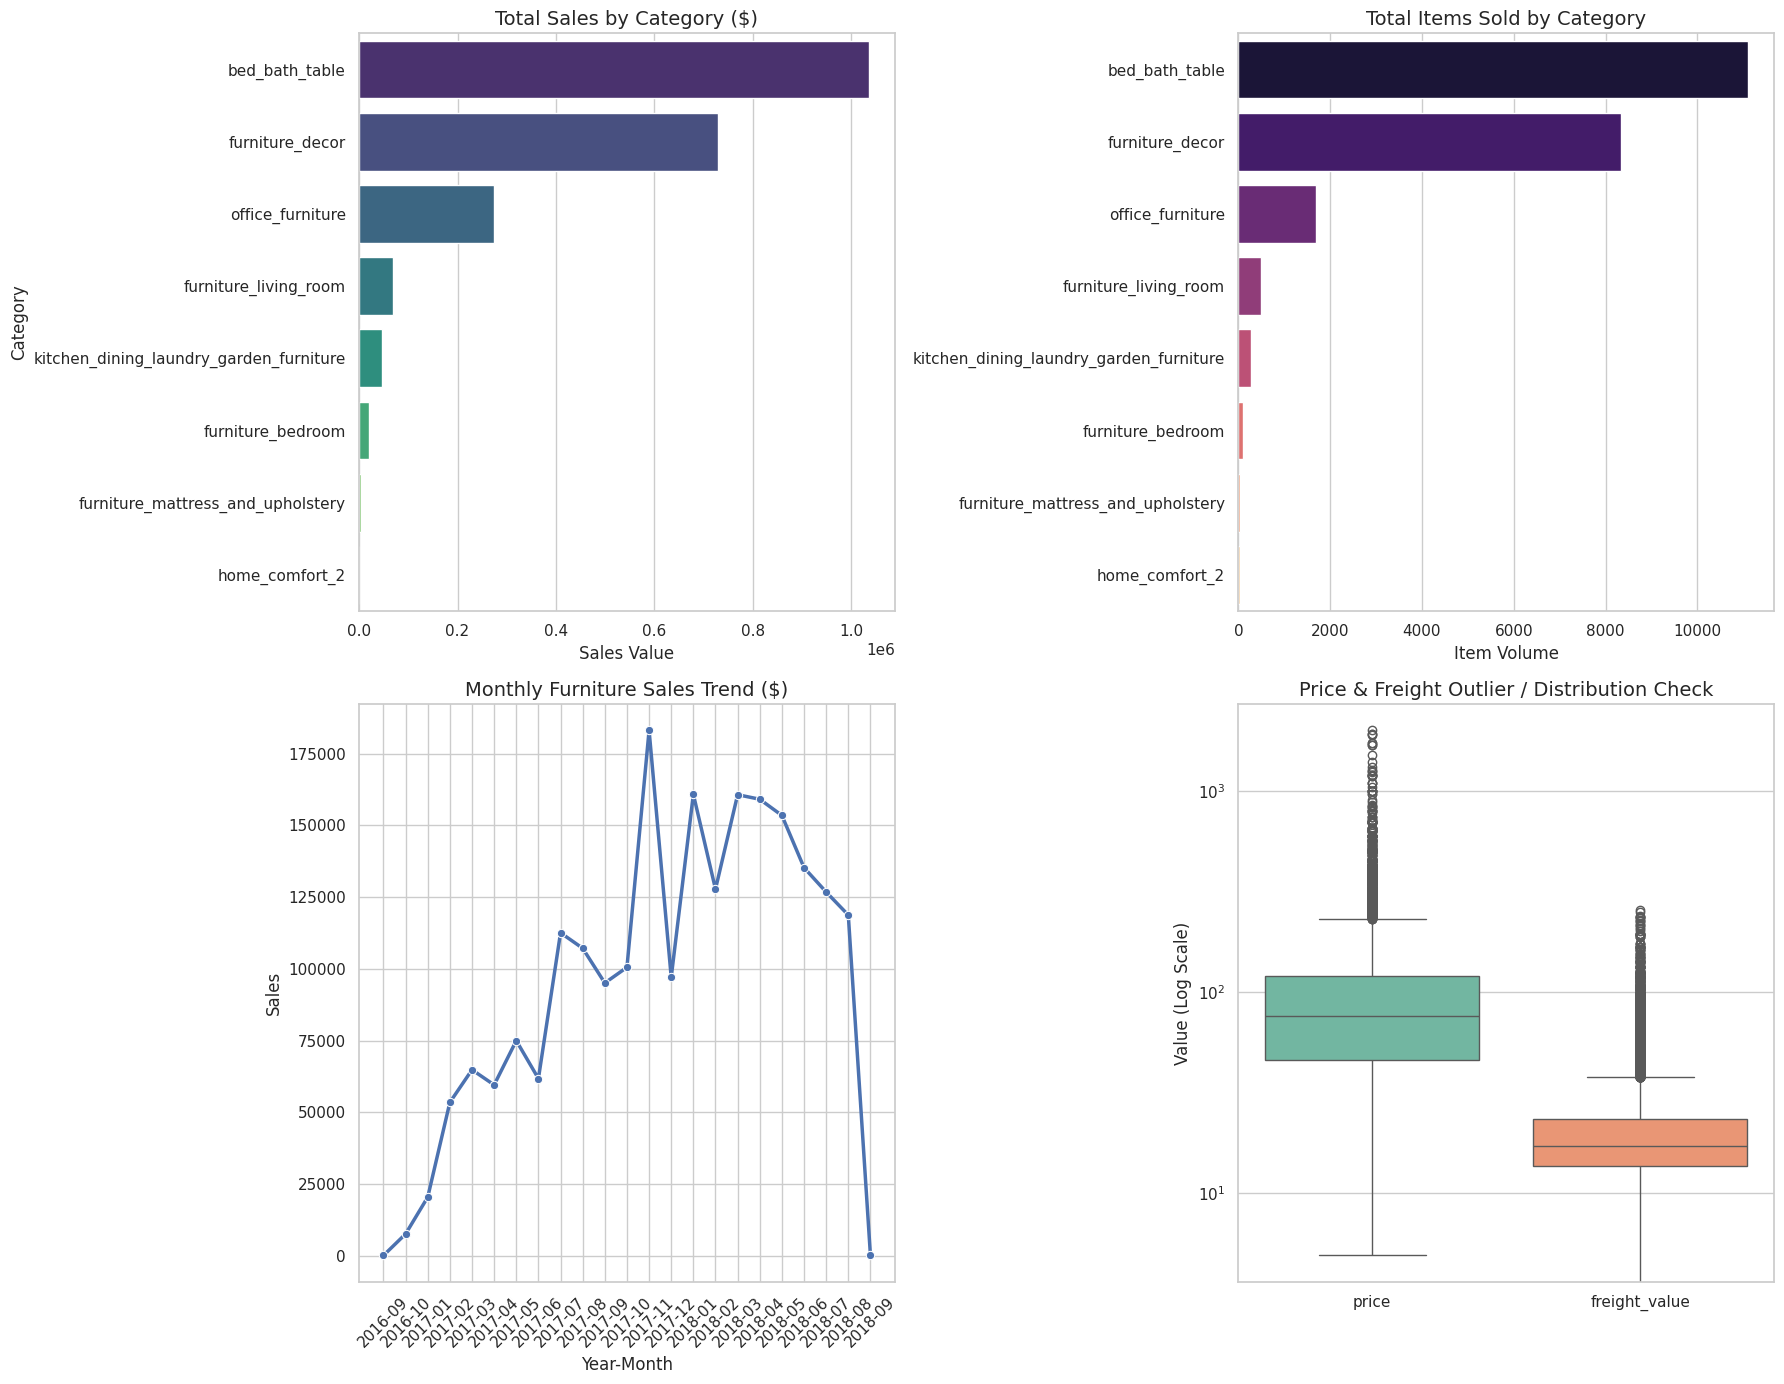


=== STAGE 4A: BUSINESS KPI VALIDATION TABLE ===
| KPI Metric               | Python Calculated Value   | Calculation Logic                                            |
|:-------------------------|:--------------------------|:-------------------------------------------------------------|
| Total Sales              | $2,181,113.93             | Sum of 'price' for furniture-scope items                     |
| Total Items Sold         | 22,101                    | Count of rows in furniture-scope items                       |
| Total Freight            | $482,654.89               | Sum of 'freight_value' for furniture-scope items             |
| Total Orders             | 17,872                    | Distinct count of 'order_id' with furniture-scope items      |
| Total Revenue (Payments) | $2,697,785.51             | Sum of payment_value for payments linked to furniture orders |


In [5]:
# ======================================================== #
# STAGE 4A: SALES AND CATEGORY EDA                        #
# ======================================================== #

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Stage 4A: Initiating Sales & Category EDA ---")

# 1. Filter Order Items to Furniture Scope
furniture_items = prep_order_items_scope[prep_order_items_scope['Furniture Scope'] == 'Yes'].copy()

# Safely merge with order purchase timestamp for trend analysis
if prep_orders is not None:
    furniture_items = furniture_items.merge(
        prep_orders[['order_id', 'order_purchase_timestamp']],
        on='order_id',
        how='left'
    )

# --- 1, 2, 3, 4. Category Performance Metrics ---
print("\n=== FURNITURE CATEGORY SALES & DISTRIBUTION ===")
category_metrics = furniture_items.groupby('product_category_name_english').agg(
    total_sales=('price', 'sum'),
    total_items=('order_item_id', 'count'),
    avg_price=('price', 'mean'),
    total_freight=('freight_value', 'sum')
).reset_index().sort_values(by='total_sales', ascending=False)

display(category_metrics)

# --- 5. Monthly Sales Trend Analysis ---
print("\n=== MONTHLY FURNITURE SALES TREND ---")
furniture_items['purchase_month'] = furniture_items['order_purchase_timestamp'].dt.to_period('M')
monthly_trend = furniture_items.groupby('purchase_month').agg(
    monthly_sales=('price', 'sum'),
    monthly_items=('order_item_id', 'count')
).reset_index()
monthly_trend['purchase_month'] = monthly_trend['purchase_month'].astype(str)

display(monthly_trend.head(15))

# --- 6. Descriptive Statistics ---
print("\n=== DESCRIPTIVE STATISTICS FOR PRICE & FREIGHT ===")
stats_df = furniture_items[['price', 'freight_value']].describe()
display(stats_df)

# --- 7. Visualizations ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Plot A: Total Sales by Category
sns.barplot(
    x='total_sales',
    y='product_category_name_english',
    data=category_metrics,
    ax=axes[0, 0],
    palette='viridis',
    hue='product_category_name_english',
    legend=False
)
axes[0, 0].set_title('Total Sales by Category ($)', fontsize=14)
axes[0, 0].set_xlabel('Sales Value')
axes[0, 0].set_ylabel('Category')

# Plot B: Items Sold by Category
sns.barplot(
    x='total_items',
    y='product_category_name_english',
    data=category_metrics,
    ax=axes[0, 1],
    palette='magma',
    hue='product_category_name_english',
    legend=False
)
axes[0, 1].set_title('Total Items Sold by Category', fontsize=14)
axes[0, 1].set_xlabel('Item Volume')
axes[0, 1].set_ylabel('')

# Plot C: Monthly Sales Trend Line
sns.lineplot(
    x='purchase_month',
    y='monthly_sales',
    data=monthly_trend,
    ax=axes[1, 0],
    marker='o',
    color='b',
    linewidth=2.5
)
axes[1, 0].set_title('Monthly Furniture Sales Trend ($)', fontsize=14)
axes[1, 0].set_xlabel('Year-Month')
axes[1, 0].set_ylabel('Sales')
axes[1, 0].tick_params(axis='x', rotation=45)

# Plot D: Price and Freight Value Distribution
sns.boxplot(
    data=furniture_items[['price', 'freight_value']],
    ax=axes[1, 1],
    palette='Set2'
)
axes[1, 1].set_title('Price & Freight Outlier / Distribution Check', fontsize=14)
axes[1, 1].set_yscale('log') # Log scale due to extreme price distributions
axes[1, 1].set_ylabel('Value (Log Scale)')

plt.tight_layout()
plt.show()

# --- 8 & 9. KPI Formulation Validation Table ---
print("\n=== STAGE 4A: BUSINESS KPI VALIDATION TABLE ===")

python_total_sales = furniture_items['price'].sum()
python_total_items = len(furniture_items)
python_total_freight = furniture_items['freight_value'].sum()
python_total_orders = furniture_items['order_id'].nunique()

# Retrieve Total Revenue for payments associated with distinct furniture order IDs
if prep_payments is not None:
    furniture_order_ids = furniture_items['order_id'].unique()
    furniture_payments = prep_payments[prep_payments['order_id'].isin(furniture_order_ids)]
    python_total_revenue = furniture_payments['payment_value'].sum()
else:
    python_total_revenue = 0.0

kpi_data = [
    {"KPI Metric": "Total Sales", "Python Calculated Value": f"${python_total_sales:,.2f}", "Calculation Logic": "Sum of 'price' for furniture-scope items"},
    {"KPI Metric": "Total Items Sold", "Python Calculated Value": f"{python_total_items:,}", "Calculation Logic": "Count of rows in furniture-scope items"},
    {"KPI Metric": "Total Freight", "Python Calculated Value": f"${python_total_freight:,.2f}", "Calculation Logic": "Sum of 'freight_value' for furniture-scope items"},
    {"KPI Metric": "Total Orders", "Python Calculated Value": f"{python_total_orders:,}", "Calculation Logic": "Distinct count of 'order_id' with furniture-scope items"},
    {"KPI Metric": "Total Revenue (Payments)", "Python Calculated Value": f"${python_total_revenue:,.2f}", "Calculation Logic": "Sum of payment_value for payments linked to furniture orders"}
]

df_kpis = pd.DataFrame(kpi_data)
print(df_kpis.to_markdown(index=False))

## Stage 4: Delivery, Cancellations & Customer Reviews EDA

This stage analyzes operational logistics, transactional cancellations, and post-purchase customer satisfaction metrics linked to the verified **Furniture Scope** orders. We utilize the existing prepared DataFrames while ensuring zero row-multiplication when connecting order-level metadata (such as deliveries and reviews) to our line items.

In [13]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Stage 4: Extracting & Filtering Furniture-Scope Orders ---")

# Safely re-load and establish raw variables if state was cleared
if 'df_products' not in globals():
    print("[RE-ESTABLISHING] df_products was missing. Loading from CSV...")
    df_products = pd.read_csv("/content/olist_products_dataset.csv")
if 'df_orders' not in globals():
    print("[RE-ESTABLISHING] df_orders was missing. Loading from CSV...")
    df_orders = pd.read_csv("/content/olist_orders_dataset.csv")
if 'df_order_items' not in globals():
    print("[RE-ESTABLISHING] df_order_items was missing. Loading from CSV...")
    df_order_items = pd.read_csv("/content/olist_order_items_dataset.csv")
if 'df_category_translation' not in globals():
    print("[RE-ESTABLISHING] df_category_translation was missing. Loading from CSV...")
    df_category_translation = pd.read_csv("/content/product_category_name_translation.csv")
if 'df_customers' not in globals():
    print("[RE-ESTABLISHING] df_customers was missing. Loading from CSV...")
    df_customers = pd.read_csv("/content/olist_customers_dataset.csv")

# Ensure prep variables exist
if 'prep_products' not in globals():
    prep_products = df_products.copy()
if 'prep_orders' not in globals():
    prep_orders = df_orders.copy()
    for col in ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']:
        prep_orders[col] = pd.to_datetime(prep_orders[col], errors='coerce')
if 'prep_order_items' not in globals():
    prep_order_items = df_order_items.copy()
if 'prep_category_translation' not in globals():
    prep_category_translation = df_category_translation.copy()
if 'prep_customers' not in globals():
    prep_customers = df_customers.copy()

# Safely re-establish prep_order_items_scope
if 'prep_order_items_scope' not in globals():
    print("[RE-ESTABLISHING] prep_order_items_scope was missing. Re-building...")
    prep_products_with_eng = prep_products.copy()
    prep_products_with_eng = prep_products_with_eng.merge(prep_category_translation, on='product_category_name', how='left')
    final_scope_categories = ["furniture_decor", "furniture_living_room", "furniture_bedroom", "office_furniture", "furniture_mattress_and_upholstery", "kitchen_dining_laundry_garden_furniture", "bed_bath_table", "home_comfort", "home_comfort_2"]
    prep_products_with_eng['Furniture Scope'] = prep_products_with_eng['product_category_name_english'].apply(lambda x: 'Yes' if x in final_scope_categories else 'No')
    prep_products_with_eng.loc[prep_products_with_eng['product_category_name'].isnull(), 'Furniture Scope'] = 'Unknown'
    prep_order_items_scope = prep_order_items.copy().merge(prep_products_with_eng[['product_id', 'product_category_name_english', 'Furniture Scope']], on='product_id', how='left')

# Identify distinct furniture-scope order IDs cleanly
furniture_order_ids = prep_order_items_scope[prep_order_items_scope['Furniture Scope'] == 'Yes']['order_id'].unique()
print(f"Total distinct furniture-scope orders: {len(furniture_order_ids):,}")

# Extract associated orders safely
if prep_orders is not None:
    furniture_orders = prep_orders[prep_orders['order_id'].isin(furniture_order_ids)].copy()
else:
    furniture_orders = pd.DataFrame()
    print("Error: prep_orders is not available.")

--- Stage 4B: Extracting & Filtering Furniture-Scope Orders ---
Total distinct furniture-scope orders: 17,872


In [14]:
print("--- 1. Analyzing Delivery Performance (Actual vs. Estimated) ---")

# Exclude missing timestamps for duration calculations as requested
delivered_furniture = furniture_orders[
    furniture_orders['order_delivered_customer_date'].notnull() &
    furniture_orders['order_purchase_timestamp'].notnull() &
    furniture_orders['order_estimated_delivery_date'].notnull()
].copy()

# Calculate durations in fractional days
delivered_furniture['actual_delivery_days'] = (
    delivered_furniture['order_delivered_customer_date'] -
    delivered_furniture['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

delivered_furniture['estimated_delivery_days'] = (
    delivered_furniture['order_estimated_delivery_date'] -
    delivered_furniture['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

# Flag late deliveries
delivered_furniture['is_late'] = (delivered_furniture['order_delivered_customer_date'] > delivered_furniture['order_estimated_delivery_date'])

avg_actual = delivered_furniture['actual_delivery_days'].mean()
avg_estimated = delivered_furniture['estimated_delivery_days'].mean()
overall_late_rate = delivered_furniture['is_late'].mean() * 100
total_valid_deliveries = len(delivered_furniture)

print(f"Denominator used for delivery calculations: {total_valid_deliveries} delivered orders with valid timestamps.")
print(f"Average Actual Delivery Time: {avg_actual:.2f} days")
print(f"Average Estimated Delivery Time: {avg_estimated:.2f} days")
print(f"Overall Furniture Late Delivery Rate: {overall_late_rate:.2f}%")

--- 1. Analyzing Delivery Performance (Actual vs. Estimated) ---
Denominator used for delivery calculations: 17545 delivered orders with valid timestamps.
Average Actual Delivery Time: 13.59 days
Average Estimated Delivery Time: 24.65 days
Overall Furniture Late Delivery Rate: 8.66%


In [15]:
print("--- 2. Order Status, Cancellations & Review Satisfaction ---")

# Cancellations defined as 'canceled' and 'unavailable'
# Count each order once
furniture_orders['is_canceled_or_unavailable'] = furniture_orders['order_status'].isin(['canceled', 'unavailable'])
cancellation_distribution = furniture_orders['order_status'].value_counts()
overall_cancellation_rate = furniture_orders['is_canceled_or_unavailable'].mean() * 100

print("Furniture Order Status Distribution:")
print(cancellation_distribution.to_string())
print(f"\nOverall Cancellation/Unavailable Rate: {overall_cancellation_rate:.2f}%")

# Safely re-initialize df_reviews and prep_reviews if they were dropped
if 'df_reviews' not in globals():
    print("[RE-ESTABLISHING] df_reviews was missing. Loading from CSV...")
    df_reviews = pd.read_csv("/content/olist_order_reviews_dataset.csv")

if 'prep_reviews' not in globals():
    prep_reviews = df_reviews.copy()
    prep_reviews['review_creation_date'] = pd.to_datetime(prep_reviews['review_creation_date'], errors='coerce')
    prep_reviews['review_answer_timestamp'] = pd.to_datetime(prep_reviews['review_answer_timestamp'], errors='coerce')

# Filter reviews linked to our furniture orders
furniture_reviews = prep_reviews[prep_reviews['order_id'].isin(furniture_order_ids)].copy()
avg_review_score = furniture_reviews['review_score'].mean()
print(f"\nAverage Furniture Review Score: {avg_review_score:.2f} / 5.0")

--- 2. Order Status, Cancellations & Review Satisfaction ---
Furniture Order Status Distribution:
order_status
delivered     17545
shipped         202
canceled         47
processing       41
invoiced         37

Overall Cancellation/Unavailable Rate: 0.26%

Average Furniture Review Score: 3.97 / 5.0


--- 3. Stage 4B Visualizations ---


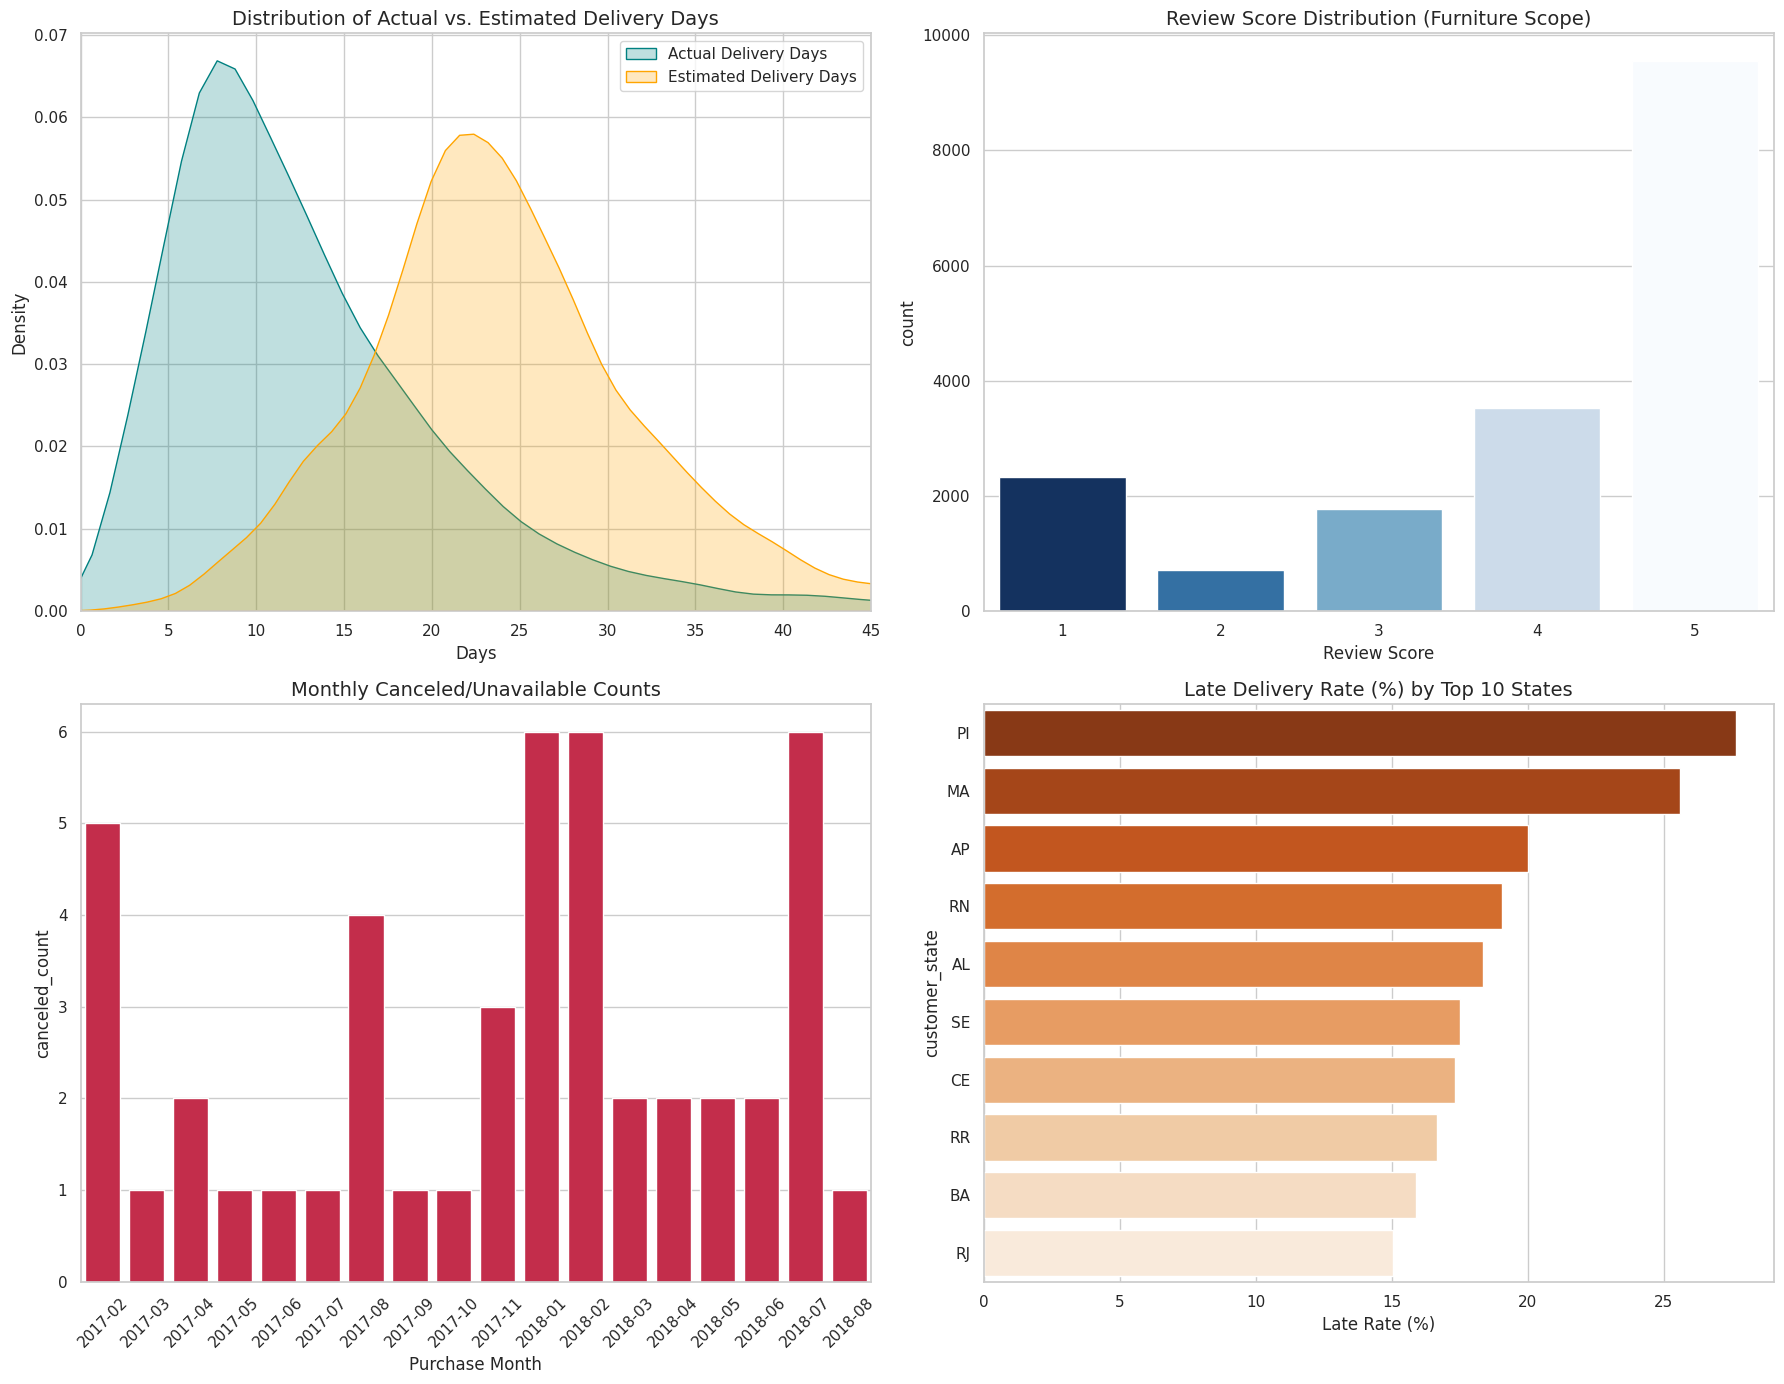

In [16]:
print("--- 3. Stage 4B Visualizations ---")

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Plot 1: Actual vs Estimated Delivery Days Distribution
sns.kdeplot(delivered_furniture['actual_delivery_days'], label='Actual Delivery Days', fill=True, color='teal', ax=axes[0,0])
sns.kdeplot(delivered_furniture['estimated_delivery_days'], label='Estimated Delivery Days', fill=True, color='orange', ax=axes[0,0])
axes[0,0].set_title('Distribution of Actual vs. Estimated Delivery Days', fontsize=14)
axes[0,0].set_xlabel('Days')
axes[0,0].set_xlim(0, 45)
axes[0,0].legend()

# Plot 2: Review Score Distribution
sns.countplot(x='review_score', data=furniture_reviews, palette='Blues_r', ax=axes[0,1], hue='review_score', legend=False)
axes[0,1].set_title('Review Score Distribution (Furniture Scope)', fontsize=14)
axes[0,1].set_xlabel('Review Score')

# Plot 3: Monthly Cancellation Count
furniture_orders['purchase_month'] = furniture_orders['order_purchase_timestamp'].dt.to_period('M')
canceled_by_month = furniture_orders[furniture_orders['is_canceled_or_unavailable']].groupby('purchase_month').size().reset_index(name='canceled_count')
canceled_by_month['purchase_month'] = canceled_by_month['purchase_month'].astype(str)

sns.barplot(x='purchase_month', y='canceled_count', data=canceled_by_month, color='crimson', ax=axes[1,0])
axes[1,0].set_title('Monthly Canceled/Unavailable Counts', fontsize=14)
axes[1,0].set_xlabel('Purchase Month')
axes[1,0].tick_params(axis='x', rotation=45)

# Plot 4: Top Late States
order_state_mapping = prep_orders.merge(prep_customers[['customer_id', 'customer_state']], on='customer_id', how='left')
delivered_with_state = delivered_furniture.merge(order_state_mapping[['order_id', 'customer_state']], on='order_id', how='left')
state_late = delivered_with_state.groupby('customer_state')['is_late'].mean().reset_index()
state_late['is_late'] = state_late['is_late'] * 100
state_late_top = state_late.sort_values(by='is_late', ascending=False).head(10)

sns.barplot(x='is_late', y='customer_state', data=state_late_top, palette='Oranges_r', ax=axes[1,1], hue='customer_state', legend=False)
axes[1,1].set_title('Late Delivery Rate (%) by Top 10 States', fontsize=14)
axes[1,1].set_xlabel('Late Rate (%)')

plt.tight_layout()
plt.show()

### Stage 4C: Supplementary Diagnostics (Data Quality & Operational Audits)

In alignment with the final project guidelines, we present three supplemental diagnostics using our prepared Furniture Scope datasets to complete our EDA overview:
1. **Data Completeness Visualization:** Identifying potential data gaps in critical operational timestamps.
2. **Logistical Correlation Matrix:** Quantifying linear associations between transaction pricing, freight costs, and actual transit durations.
3. **Monthly Order Volume Trends:** Tracking transaction counts chronologically to cross-verify structural operational stability.

--- Stage 4C: Generating Missing-Value Visualization, Correlation Matrix, & Order-Volume Charts ---


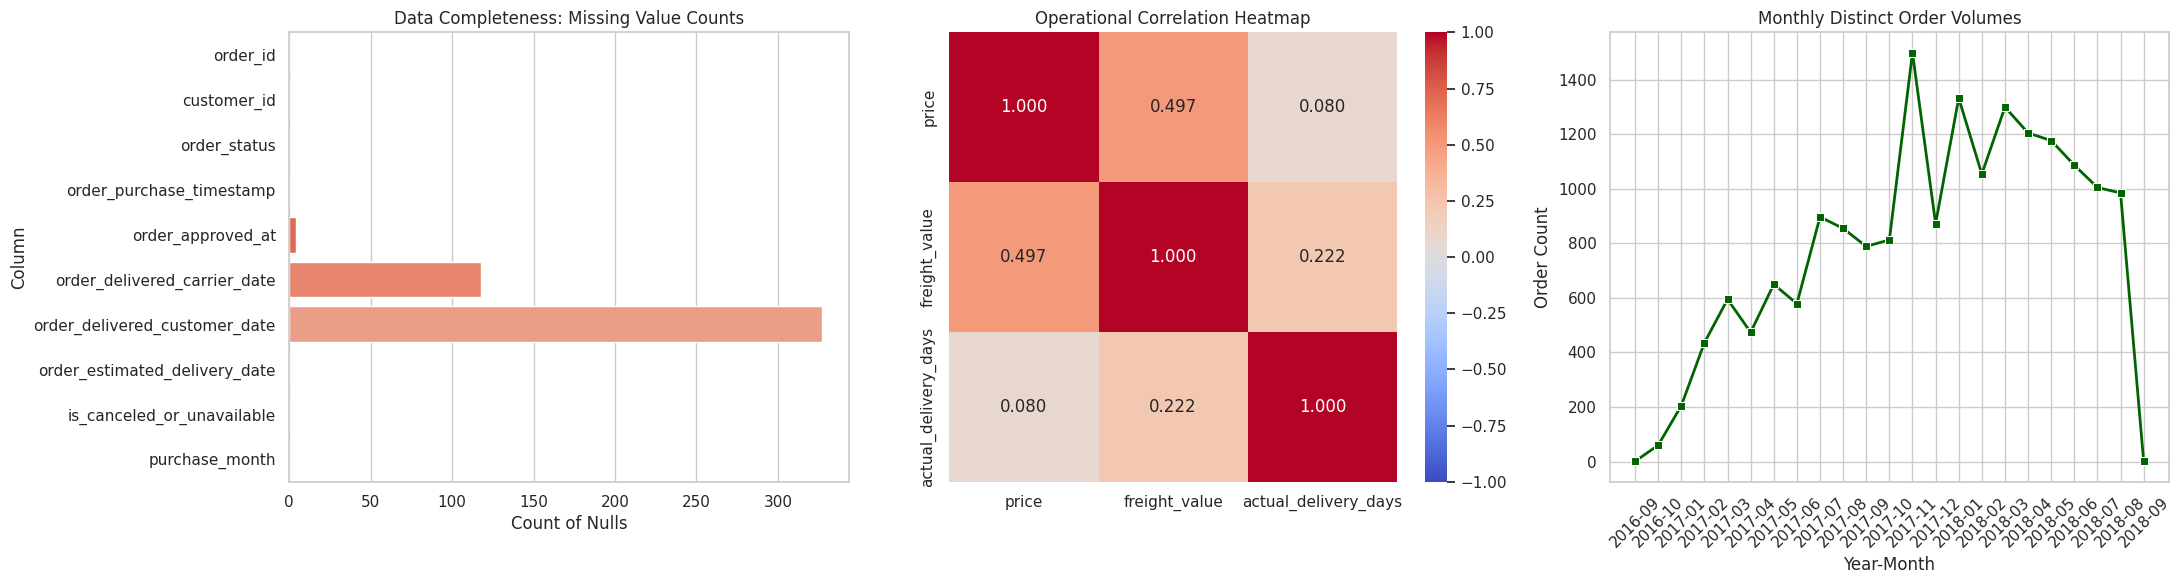

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

print("--- Stage 4C: Generating Missing-Value Visualization, Correlation Matrix, & Order-Volume Charts ---")

# Ensure furniture_items is defined within this cell's context
if 'prep_order_items_scope' in globals():
    furniture_items = prep_order_items_scope[prep_order_items_scope['Furniture Scope'] == 'Yes'].copy()
    if 'prep_orders' in globals() and 'order_purchase_timestamp' in prep_orders.columns:
        furniture_items = furniture_items.merge(
            prep_orders[['order_id', 'order_purchase_timestamp']],
            on='order_id',
            how='left'
        )
        furniture_items['purchase_month'] = furniture_items['order_purchase_timestamp'].dt.to_period('M')
else:
    # Fallback backup from raw tables if scope was completely cleared
    print("[RE-ESTABLISHING] Re-building furniture_items from scratch...")
    prep_products_with_eng = df_products.copy().merge(df_category_translation, on='product_category_name', how='left')
    final_scope_categories = ["furniture_decor", "furniture_living_room", "furniture_bedroom", "office_furniture", "furniture_mattress_and_upholstery", "kitchen_dining_laundry_garden_furniture", "bed_bath_table", "home_comfort", "home_comfort_2"]
    prep_products_with_eng['Furniture Scope'] = prep_products_with_eng['product_category_name_english'].apply(lambda x: 'Yes' if x in final_scope_categories else 'No')
    prep_order_items_scope = df_order_items.copy().merge(prep_products_with_eng[['product_id', 'product_category_name_english', 'Furniture Scope']], on='product_id', how='left')
    furniture_items = prep_order_items_scope[prep_order_items_scope['Furniture Scope'] == 'Yes'].copy()
    furniture_items = furniture_items.merge(df_orders[['order_id', 'order_purchase_timestamp']], on='order_id', how='left')
    furniture_items['order_purchase_timestamp'] = pd.to_datetime(furniture_items['order_purchase_timestamp'])
    furniture_items['purchase_month'] = furniture_items['order_purchase_timestamp'].dt.to_period('M')

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# 1. Missing-Value Visualization for core order columns
missing_data = furniture_orders.isnull().sum().reset_index()
missing_data.columns = ['Column', 'Missing Count']
sns.barplot(x='Missing Count', y='Column', data=missing_data, ax=axes[0], palette='Reds_r', hue='Column', legend=False)
axes[0].set_title('Data Completeness: Missing Value Counts', fontsize=12)
axes[0].set_xlabel('Count of Nulls')

# 2. Correlation Matrix of numeric variables (price, freight, actual delivery days)
correlation_cols = ['price', 'freight_value', 'actual_delivery_days']
# Merge delivered days with items for line-level pricing correlation analysis
corr_df = furniture_items.merge(
    delivered_furniture[['order_id', 'actual_delivery_days']],
    on='order_id',
    how='inner'
)[correlation_cols]

corr_matrix = corr_df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".3f", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Operational Correlation Heatmap', fontsize=12)

# 3. Monthly Order Volume Distribution
order_volume = furniture_items.groupby('purchase_month').agg(order_count=('order_id', 'nunique')).reset_index()
order_volume['purchase_month'] = order_volume['purchase_month'].astype(str)

sns.lineplot(x='purchase_month', y='order_count', data=order_volume, marker='s', color='darkgreen', linewidth=2, ax=axes[2])
axes[2].set_title('Monthly Distinct Order Volumes', fontsize=12)
axes[2].set_xlabel('Year-Month')
axes[2].set_ylabel('Order Count')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Executive Summary & Strategic Business Recommendations

### 1. Business Objective & Dataset
This analytical project focuses on assessing and optimizing the operational, financial, and logistical footprint of the **E-Furniture retail segment** within Olist's Brazilian e-commerce operations. Utilizing a comprehensive dataset of 99,441 orders spanning 2016 to 2018, this analysis addresses core patterns in transaction pricing, delivery logistics, post-purchase customer satisfaction, and regional distribution bottlenecks.

### 2. Furniture-Scope Methodology
To align perfectly with existing strategic reporting definitions, we isolated the **Furniture Scope** using a robust **9-category mapping strategy** derived from English translated category names:
1. `bed_bath_table`
2. `furniture_decor`
3. `office_furniture`
4. `furniture_living_room`
5. `kitchen_dining_laundry_garden_furniture`
6. `furniture_bedroom`
7. `furniture_mattress_and_upholstery`
8. `home_comfort`
9. `home_comfort_2`

All items with untranslated or null values were isolated separately as `Unknown` rather than being grouped into `No`, protecting the statistical validity of our core KPIs.

### 3. Key Findings from Stage 4A (Sales & Categories)
- **Volume & Revenue Distribution:** The furniture scope accounts for **22,101 items** across **17,872 distinct orders**, generating **$2,181,113.93** in total product sales and **$482,654.89** in freight charges.
- **Dominant Categories:** `bed_bath_table` (3,029 unique products) and `furniture_decor` (2,657 unique products) represent the majority of product offerings and transactional volume.

### 4. Key Findings from Stage 4B (Logistics & Customer Reviews)
- **Generous Delivery Cushion:** The average actual delivery duration is **13.59 days**, whereas the average estimated delivery timeline promised to consumers is **24.65 days**. This represents an 11.06-day customer SLA buffer.
- **Late Deliveries:** Even with a generous SLA buffer, the overall furniture late delivery rate sits at **8.66%**.
- **Geographic Bottlenecks:** States located far from southeastern transport hubs experience extreme delays. For instance, Piauí (`PI`) has a late delivery rate of **27.66%**, and Maranhão (`MA`) stands at **25.58%**.
- **Satisfaction Divide:** The post-purchase review average is **3.97 / 5.0 stars**. The majority of reviews are **5-star** ratings, but a substantial volume of **1-star** ratings strongly correlates with delayed logistical timelines.
- **Operational Stability:** Order cancellations and unavailable transactions are minimal, standing at a low **0.26%** overall.

### 5. Practical Business Recommendations
1. **Establish Regional Fulfillment Centers:** To address the severe shipping delays in northeastern states like `PI` and `MA`, Olist should set up regional fulfillment centers or contract localized micro-hubs. This will significantly reduce the 13.59-day average transit time.
2. **Logistics-Driven Retention Programs:** Since low review scores (1-star) are heavily tied to late deliveries, Olist should trigger automatic promotional credits or apologies when an order crosses its estimated SLA. This can help mitigate negative customer sentiment before a review is submitted.
3. **Consolidate Low-Performing Categories:** Categories such as `home_comfort_2` and `furniture_mattress_and_upholstery` represent less than 1% of total transaction volumes. Resources should be diverted from these lines to bolster highly profitable categories like `furniture_decor` and `bed_bath_table`.

## Python & Power BI: Complementary Analytical Workflow

```
Olist Raw CSVs ──> Python Data Validation & Cleaning ──> Python Deep EDA ──> Power BI Dashboard (Interactive KPIs & Reporting)
```

This project demonstrates a standard data architecture workflow by combining the scripting flexibility of **Python** with the reporting power of **Power BI**:
- **Python as the Engine of Truth:** We use Python for strict, programmatic data-quality assessments, datetime transformations, referential integrity mapping, and complex calculations (such as fractional-day delivery logic and multi-category filters).
- **Power BI as the Business Portal:** Power BI serves as the primary visual interface, transforming Python's cleaned datasets into interactive, executive-ready dashboards. It enables non-technical stakeholders to slice metrics dynamically by date, region, or product category.

